# Retail Sales Forecasting & Inventory Optimization

Renajwa Naylafasya

## 1. Project Overview

### 1.1 Background

Retail businesses rely on historical sales data to understand customer demand and manage product inventory. However, fluctuations in sales patterns, seasonal trends, promotional activities, and store characteristics can make demand difficult to predict accurately.

Inaccurate sales forecasting may lead to overstocking, which increases inventory holding costs, or stockouts, which can result in missed sales opportunities. Therefore, predictive analytics can help retailers estimate future product demand and support more informed inventory planning.

This project applies machine learning techniques to historical retail sales data to develop a forecasting model that predicts daily product sales across different stores and product categories. The resulting predictions are further utilized to generate inventory planning recommendations.

### 1.2 Business Problem

The main problem addressed in this project is the difficulty of estimating future product demand across multiple retail stores and product categories.

The project focuses on the following business challenges:

- Uncertainty in daily product sales and demand patterns.
- Differences in sales performance across stores and product categories.
- The need to evaluate forecasting accuracy using different machine learning approaches.
- The risk of inventory imbalance due to inaccurate demand estimation.

### 1.3 Project Objectives

The objectives of this project are:

1. To analyze historical retail sales patterns across stores and product categories.
2. To develop daily sales forecasting models using Seasonal Naive, Random Forest Regressor, and XGBoost Regressor.
3. To compare model performance using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Weighted Absolute Percentage Error (WAPE).
4. To identify the best-performing forecasting model based on evaluation results.
5. To utilize predicted sales as a basis for inventory planning recommendations.

### 1.4 Project Scope

This project focuses on daily sales forecasting at the store and product family level using the Store Sales - Time Series Forecasting dataset from Corporación Favorita.

The scope includes:

- Data integration and preprocessing.
- Exploratory Data Analysis (EDA).
- Feature engineering using historical sales, calendar information, store characteristics, and other relevant variables.
- Development and comparison of three forecasting models.
- Model evaluation using MAE, RMSE, and WAPE.
- Inventory planning simulation using predicted demand, assumed lead time, and safety stock parameters.
- Development of an interactive dashboard using Streamlit.

The inventory planning component is designed as a decision-support simulation because actual inventory records and replenishment lead times are not provided in the dataset.

### 1.5 Dataset Description

The primary dataset used in this project is **Store Sales - Time Series Forecasting**, published by Corporación Favorita.

The dataset contains historical retail sales records and supporting information, including:

| Dataset | Description |
|---|---|
| train.csv | Historical daily sales, store, product family, and promotional data |
| stores.csv | Store location and classification information |
| oil.csv | Daily oil prices |
| holidays_events.csv | Holiday and event information |
| transactions.csv | Daily transaction counts by store |

These datasets are integrated to construct a unified dataset for exploratory analysis and predictive modeling.

### 1.6 Technology Stack

| Category | Tools |
|---|---|
| Programming Language | Python |
| Data Processing | Pandas, NumPy |
| Data Visualization | Matplotlib, Seaborn, Plotly |
| Machine Learning | Scikit-learn, XGBoost |
| Development Environment | Jupyter Notebook |
| Dashboard | Streamlit |
| Version Control | Git & GitHub |

### 1.7 Expected Deliverables

The expected outputs of this project include:

1. A processed and integrated retail sales dataset.
2. Exploratory analysis of retail sales trends and patterns.
3. Three trained forecasting models.
4. Model performance comparison using MAE, RMSE, and WAPE.
5. Daily sales predictions for selected stores and product categories.
6. Inventory planning recommendations based on forecasted demand.
7. An interactive Streamlit dashboard for retail sales analysis, forecasting, and inventory decision support.

#Data Loading


In [1]:
import pandas as pd
import numpy as np
import os
import warnings

warnings.filterwarnings("ignore")

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

train = pd.read_csv(io.BytesIO(uploaded['train.csv']))
stores = pd.read_csv(io.BytesIO(uploaded['stores.csv']))
oil = pd.read_csv(io.BytesIO(uploaded['oil.csv']))
holidays = pd.read_csv(io.BytesIO(uploaded['holidays_events.csv']))
transactions = pd.read_csv(io.BytesIO(uploaded['transactions.csv']))

Saving train.csv to train.csv
Saving transactions.csv to transactions.csv
Saving holidays_events.csv to holidays_events.csv
Saving oil.csv to oil.csv
Saving stores.csv to stores.csv


#Data Understanding


In [3]:
# Check dataset dimensions
datasets = {
    "Train": train,
    "Stores": stores,
    "Oil": oil,
    "Holidays": holidays,
    "Transactions": transactions
}

for name, df in datasets.items():
    print(f"\n{name}")
    print(f"Shape: {df.shape}")
    display(df.head(3))


Train
Shape: (3000888, 6)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.00,0
1,1,2013-01-01,1,BABY CARE,0.00,0
2,2,2013-01-01,1,BEAUTY,0.00,0



Stores
Shape: (54, 5)


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8



Oil
Shape: (1218, 2)


,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97



Holidays
Shape: (350, 6)


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False



Transactions
Shape: (83488, 3)


,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358


In [4]:
for name, df in datasets.items():
    print(f"\n===== {name} =====")
    df.info()
    print("\nMissing Values:")
    display(df.isnull().sum().to_frame("Missing Values"))


===== Train =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         object 
 2   store_nbr    int64  
 3   family       object 
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 137.4+ MB

Missing Values:


,Missing Values
id,0
date,0
store_nbr,0
family,0
sales,0
onpromotion,0



===== Stores =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   store_nbr  54 non-null     int64 
 1   city       54 non-null     object
 2   state      54 non-null     object
 3   type       54 non-null     object
 4   cluster    54 non-null     int64 
dtypes: int64(2), object(3)
memory usage: 2.2+ KB

Missing Values:


,Missing Values
store_nbr,0
city,0
state,0
type,0
cluster,0



===== Oil =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        1218 non-null   object 
 1   dcoilwtico  1175 non-null   float64
dtypes: float64(1), object(1)
memory usage: 19.2+ KB

Missing Values:


,Missing Values
date,0
dcoilwtico,43



===== Holidays =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   date         350 non-null    object
 1   type         350 non-null    object
 2   locale       350 non-null    object
 3   locale_name  350 non-null    object
 4   description  350 non-null    object
 5   transferred  350 non-null    bool  
dtypes: bool(1), object(5)
memory usage: 14.1+ KB

Missing Values:


,Missing Values
date,0
type,0
locale,0
locale_name,0
description,0
transferred,0



===== Transactions =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83488 entries, 0 to 83487
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   date          83488 non-null  object
 1   store_nbr     83488 non-null  int64 
 2   transactions  83488 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 1.9+ MB

Missing Values:


,Missing Values
date,0
store_nbr,0
transactions,0


#Exploratory Data Analysis (EDA)

In [5]:
# Convert date columns for exploration
train['date'] = pd.to_datetime(train['date'])

print("Sales Date Range:")
print(f"Start Date: {train['date'].min()}")
print(f"End Date: {train['date'].max()}")

print("\nUnique Values:")
print(f"Stores: {train['store_nbr'].nunique()}")
print(f"Product Families: {train['family'].nunique()}")
print(f"Dates: {train['date'].nunique()}")

Sales Date Range:
Start Date: 2013-01-01 00:00:00
End Date: 2017-08-15 00:00:00

Unique Values:
Stores: 54
Product Families: 33
Dates: 1684


In [6]:
train['sales'].describe()

,sales
count,3000888.00
mean,357.78
std,1102.00
min,0.00
25%,0.00
50%,11.00
75%,195.85
max,124717.00


In [7]:
sales_by_family = (
    train.groupby('family')['sales']
    .sum()
    .sort_values(ascending=False)
)

display(sales_by_family.to_frame('total_sales'))

,total_sales
family,
GROCERY I,343462734.89
BEVERAGES,216954486.00
PRODUCE,122704684.68
CLEANING,97521289.00
DAIRY,64487709.00
BREAD/BAKERY,42133945.58
POULTRY,31876004.47
MEATS,31086468.40
PERSONAL CARE,24592051.00


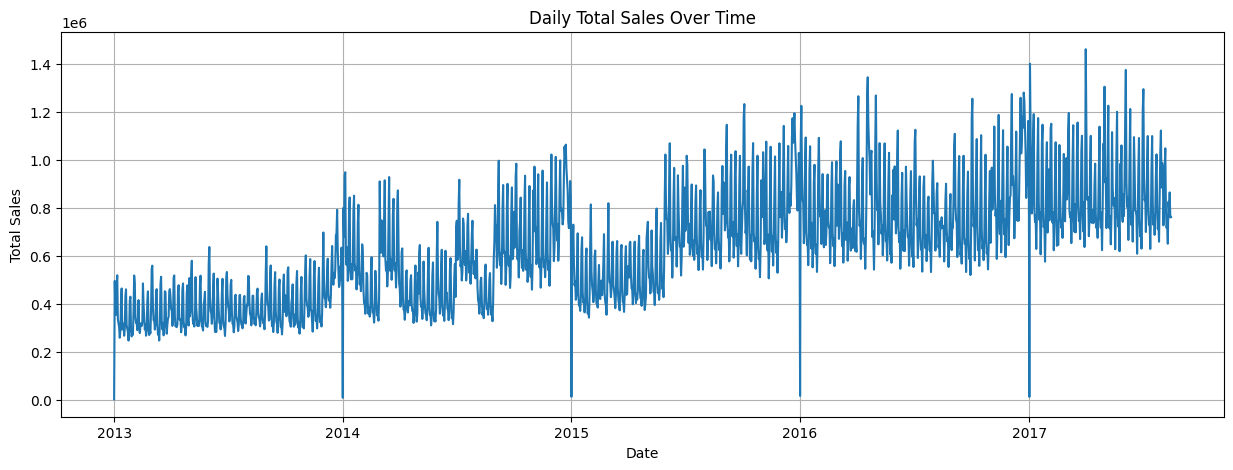

In [8]:
import matplotlib.pyplot as plt

daily_sales = train.groupby('date')['sales'].sum()

plt.figure(figsize=(15, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title('Daily Total Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.grid(True)
plt.show()

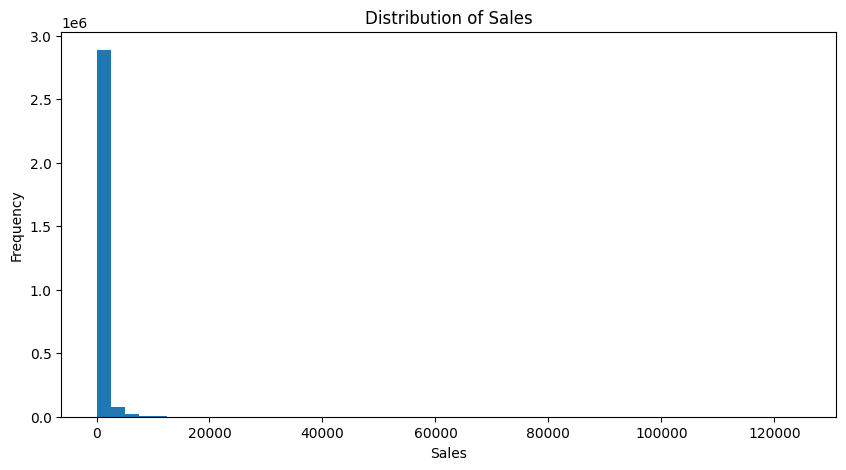

In [9]:
plt.figure(figsize=(10, 5))
plt.hist(train['sales'], bins=50)
plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

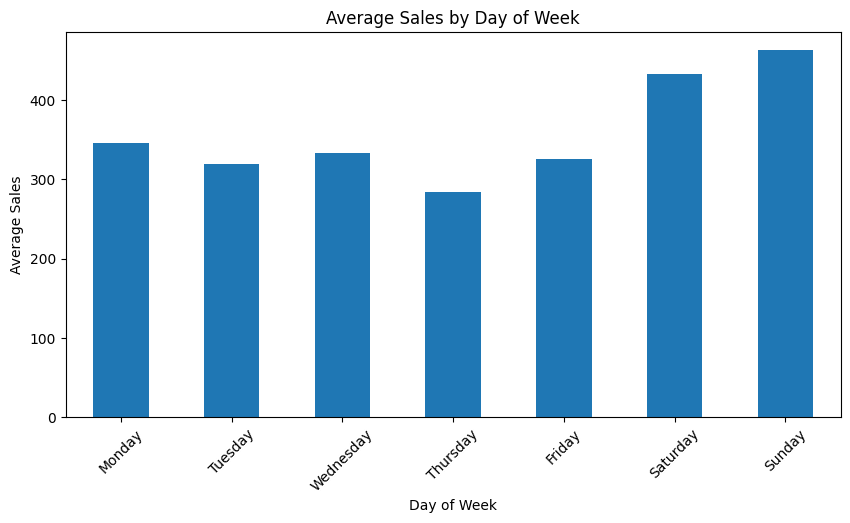

In [10]:
train['day_of_week'] = train['date'].dt.day_name()

weekly_sales = (
    train.groupby('day_of_week')['sales']
    .mean()
    .reindex([
        'Monday', 'Tuesday', 'Wednesday',
        'Thursday', 'Friday', 'Saturday', 'Sunday'
    ])
)

weekly_sales.plot(
    kind='bar',
    figsize=(10, 5),
    title='Average Sales by Day of Week',
    xlabel='Day of Week',
    ylabel='Average Sales'
)

plt.xticks(rotation=45)
plt.show()

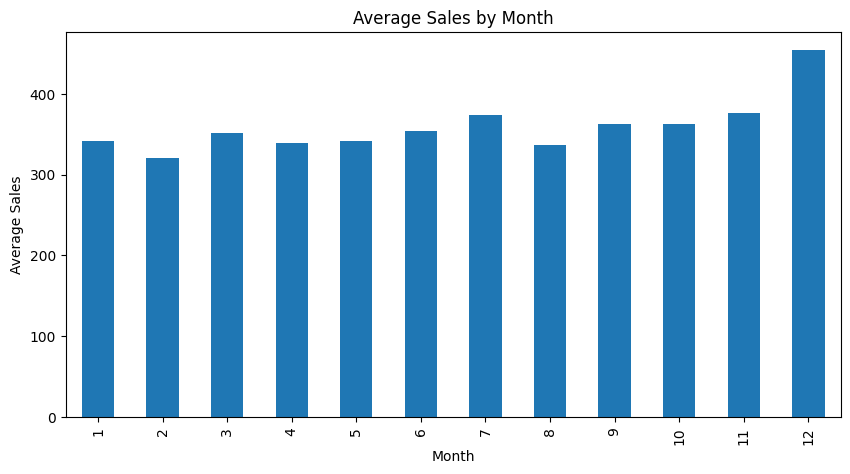

In [11]:
train['month'] = train['date'].dt.month

monthly_sales = train.groupby('month')['sales'].mean()

monthly_sales.plot(
    kind='bar',
    figsize=(10, 5),
    title='Average Sales by Month',
    xlabel='Month',
    ylabel='Average Sales'
)

plt.show()

The exploratory data analysis revealed several important characteristics of the retail sales dataset:

1. **Dataset Coverage and Scale**

   The dataset contains 3,000,888 observations covering daily retail sales from January 1, 2013, to August 15, 2017. It includes 54 stores and 33 product families, providing a substantial historical dataset for developing daily sales forecasting models.

2. **Sales Distribution and Variability**

   Descriptive statistics indicate an average sales value of approximately 357.78, with a standard deviation of 1,102.00. The presence of zero-sales observations and substantial variation suggests that sales patterns differ considerably across stores, product families, and dates.

3. **Sales Contribution by Product Family**

   Grocery I recorded the highest cumulative sales, followed by Beverages and Produce. This indicates that essential consumer product categories contribute substantially to overall retail sales and should receive particular attention in the forecasting analysis.

4. **Daily Sales Trends**

   The daily sales visualization indicates an overall upward movement in retail sales throughout the observation period, accompanied by recurring fluctuations. These patterns suggest that temporal features, including long-term trends, weekly patterns, and calendar effects, may be relevant to the forecasting process.

5. **Sales Distribution Characteristics**

   Sales values exhibit a positively skewed distribution, where most observations are concentrated at relatively low values, while a smaller number of observations have substantially higher sales. This characteristic will be considered during model development and evaluation.

These findings provide an initial understanding of the dataset and help identify relevant characteristics for subsequent preprocessing, feature engineering, and forecasting model development.

#Data Preprocessing

In [12]:
# Create copies to preserve original datasets
train_clean = train.copy()
stores_clean = stores.copy()
oil_clean = oil.copy()
holidays_clean = holidays.copy()
transactions_clean = transactions.copy()

# Convert date columns to datetime
date_columns = {
    'train': train_clean,
    'oil': oil_clean,
    'holidays': holidays_clean,
    'transactions': transactions_clean
}

for name, df in date_columns.items():
    df['date'] = pd.to_datetime(df['date'])

print("Date conversion completed.")

Date conversion completed.


In [13]:
# Check duplicate records in each dataset
datasets_clean = {
    'Train': train_clean,
    'Stores': stores_clean,
    'Oil': oil_clean,
    'Holidays': holidays_clean,
    'Transactions': transactions_clean
}

for name, df in datasets_clean.items():
    print(f"{name}: {df.duplicated().sum()} duplicate rows")

Train: 0 duplicate rows
Stores: 0 duplicate rows
Oil: 0 duplicate rows
Holidays: 0 duplicate rows
Transactions: 0 duplicate rows


In [14]:
# Check negative sales
print("Negative sales:", (train_clean['sales'] < 0).sum())

# Check zero sales
print("Zero sales:", (train_clean['sales'] == 0).sum())

# Check missing values after date conversion
for name, df in datasets_clean.items():
    print(f"\n{name}")
    display(df.isnull().sum().to_frame('Missing Values'))

Negative sales: 0
Zero sales: 939130

Train


,Missing Values
id,0
date,0
store_nbr,0
family,0
sales,0
onpromotion,0
day_of_week,0
month,0



Stores


,Missing Values
store_nbr,0
city,0
state,0
type,0
cluster,0



Oil


,Missing Values
date,0
dcoilwtico,43



Holidays


,Missing Values
date,0
type,0
locale,0
locale_name,0
description,0
transferred,0



Transactions


,Missing Values
date,0
store_nbr,0
transactions,0


In [15]:
print(
    "Duplicate train keys:",
    train_clean.duplicated(
        subset=['date', 'store_nbr', 'family']
    ).sum()
)

print(
    "Duplicate transaction keys:",
    transactions_clean.duplicated(
        subset=['date', 'store_nbr']
    ).sum()
)

print(
    "Duplicate store keys:",
    stores_clean.duplicated(
        subset=['store_nbr']
    ).sum()
)

print(
    "Duplicate oil dates:",
    oil_clean.duplicated(
        subset=['date']
    ).sum()
)

Duplicate train keys: 0
Duplicate transaction keys: 0
Duplicate store keys: 0
Duplicate oil dates: 0


In [16]:
# Identify missing oil price dates
missing_oil = oil_clean[oil_clean['dcoilwtico'].isnull()]

print("Number of missing oil prices:", len(missing_oil))
display(missing_oil)

Number of missing oil prices: 43


,date,dcoilwtico
0,2013-01-01,NaN
14,2013-01-21,NaN
34,2013-02-18,NaN
63,2013-03-29,NaN
104,2013-05-27,NaN
132,2013-07-04,NaN
174,2013-09-02,NaN
237,2013-11-28,NaN
256,2013-12-25,NaN
261,2014-01-01,NaN


In [17]:
print("First available oil price:")
print(oil_clean['date'].min())

print("\nLast available oil price:")
print(oil_clean['date'].max())

print("\nMissing date range:")
print(missing_oil['date'].min())
print(missing_oil['date'].max())

First available oil price:
2013-01-01 00:00:00

Last available oil price:
2017-08-31 00:00:00

Missing date range:
2013-01-01 00:00:00
2017-07-04 00:00:00


In [18]:
# Sort oil data by date
oil_clean = oil_clean.sort_values('date').reset_index(drop=True)

# Apply forward fill
oil_clean['dcoilwtico'] = oil_clean['dcoilwtico'].ffill()

# Check remaining missing values
print("Missing values after imputation:")
print(oil_clean['dcoilwtico'].isnull().sum())

Missing values after imputation:
1


In [19]:
# Compare before and after imputation
print("Original missing values:", oil['dcoilwtico'].isnull().sum())
print("Remaining missing values:", oil_clean['dcoilwtico'].isnull().sum())

# Display previously missing dates
display(
    oil_clean[
        oil_clean['date'].isin(missing_oil['date'])
    ]
)

Original missing values: 43
Remaining missing values: 1


,date,dcoilwtico
0,2013-01-01,NaN
14,2013-01-21,95.61
34,2013-02-18,95.95
63,2013-03-29,97.24
104,2013-05-27,93.84
132,2013-07-04,101.92
174,2013-09-02,107.98
237,2013-11-28,92.05
256,2013-12-25,98.87
261,2014-01-01,98.17


In [20]:
# Merge sales data with store information
df = train_clean.merge(
    stores_clean,
    on='store_nbr',
    how='left',
    validate='many_to_one'
)

print("Shape after merging stores:", df.shape)
display(df.head())

Shape after merging stores: (3000888, 12)


,id,date,store_nbr,family,sales,onpromotion,day_of_week,month,city,state,type,cluster
0,0,2013-01-01,1,AUTOMOTIVE,0.00,0,Tuesday,1,Quito,Pichincha,D,13
1,1,2013-01-01,1,BABY CARE,0.00,0,Tuesday,1,Quito,Pichincha,D,13
2,2,2013-01-01,1,BEAUTY,0.00,0,Tuesday,1,Quito,Pichincha,D,13
3,3,2013-01-01,1,BEVERAGES,0.00,0,Tuesday,1,Quito,Pichincha,D,13
4,4,2013-01-01,1,BOOKS,0.00,0,Tuesday,1,Quito,Pichincha,D,13


In [21]:
# Merge oil price information
df = df.merge(
    oil_clean[['date', 'dcoilwtico']],
    on='date',
    how='left',
    validate='many_to_one'
)

print("Shape after merging oil:", df.shape)
display(df.head())

Shape after merging oil: (3000888, 13)


,id,date,store_nbr,family,sales,onpromotion,day_of_week,month,city,state,type,cluster,dcoilwtico
0,0,2013-01-01,1,AUTOMOTIVE,0.00,0,Tuesday,1,Quito,Pichincha,D,13,NaN
1,1,2013-01-01,1,BABY CARE,0.00,0,Tuesday,1,Quito,Pichincha,D,13,NaN
2,2,2013-01-01,1,BEAUTY,0.00,0,Tuesday,1,Quito,Pichincha,D,13,NaN
3,3,2013-01-01,1,BEVERAGES,0.00,0,Tuesday,1,Quito,Pichincha,D,13,NaN
4,4,2013-01-01,1,BOOKS,0.00,0,Tuesday,1,Quito,Pichincha,D,13,NaN


In [22]:
# Merge transaction information
df = df.merge(
    transactions_clean,
    on=['date', 'store_nbr'],
    how='left',
    validate='many_to_one'
)

print("Shape after merging transactions:", df.shape)
display(df.head())

Shape after merging transactions: (3000888, 14)


,id,date,store_nbr,family,sales,onpromotion,day_of_week,month,city,state,type,cluster,dcoilwtico,transactions
0,0,2013-01-01,1,AUTOMOTIVE,0.00,0,Tuesday,1,Quito,Pichincha,D,13,NaN,NaN
1,1,2013-01-01,1,BABY CARE,0.00,0,Tuesday,1,Quito,Pichincha,D,13,NaN,NaN
2,2,2013-01-01,1,BEAUTY,0.00,0,Tuesday,1,Quito,Pichincha,D,13,NaN,NaN
3,3,2013-01-01,1,BEVERAGES,0.00,0,Tuesday,1,Quito,Pichincha,D,13,NaN,NaN
4,4,2013-01-01,1,BOOKS,0.00,0,Tuesday,1,Quito,Pichincha,D,13,NaN,NaN


In [23]:
# Create a clean holiday dataset
holidays_active = holidays_clean[
    holidays_clean['transferred'] == False
].copy()

# Standardize location names for matching
for col in ['locale', 'locale_name', 'type']:
    holidays_active[col] = holidays_active[col].str.strip()

stores_location = stores_clean.copy()

for col in ['city', 'state']:
    stores_location[col] = stores_location[col].str.strip()

# Create store-holiday combinations
store_holidays = stores_location.merge(
    holidays_active,
    how='cross'
)

# Identify holidays applicable to each store
national = store_holidays['locale'].eq('National')

regional = (
    store_holidays['locale'].eq('Regional') &
    store_holidays['locale_name'].eq(store_holidays['state'])
)

local = (
    store_holidays['locale'].eq('Local') &
    store_holidays['locale_name'].eq(store_holidays['city'])
)

store_holidays = store_holidays[national | regional | local].copy()

print("Applicable store-holiday records:", len(store_holidays))
display(store_holidays.head())

Applicable store-holiday records: 9488


,store_nbr,city,state,type_x,cluster,date,type_y,locale,locale_name,description,transferred
14,1,Quito,Pichincha,D,13,2012-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,False
19,1,Quito,Pichincha,D,13,2012-10-12,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
20,1,Quito,Pichincha,D,13,2012-11-02,Holiday,National,Ecuador,Dia de Difuntos,False
21,1,Quito,Pichincha,D,13,2012-11-03,Holiday,National,Ecuador,Independencia de Cuenca,False
27,1,Quito,Pichincha,D,13,2012-12-05,Additional,Local,Quito,Fundacion de Quito-1,False


In [26]:
# Create holiday indicators
store_holidays['is_holiday'] = (
    store_holidays['type_y'].isin([
        'Holiday',
        'Additional',
        'Bridge'
    ])
).astype(int)

store_holidays['is_event'] = (
    store_holidays['type_y'] == 'Event'
).astype(int)

store_holidays['is_work_day'] = (
    store_holidays['type_y'] == 'Work Day'
).astype(int)

# Aggregate by store and date
holiday_features = (
    store_holidays
    .groupby(['store_nbr', 'date'], as_index=False)
    .agg({
        'is_holiday': 'max',
        'is_event': 'max',
        'is_work_day': 'max'
    })
)

display(holiday_features.head())

print("Holiday features shape:", holiday_features.shape)

,store_nbr,date,is_holiday,is_event,is_work_day
0,1,2012-08-10,1,0,0
1,1,2012-10-12,0,0,0
2,1,2012-11-02,1,0,0
3,1,2012-11-03,1,0,0
4,1,2012-12-05,1,0,0


Holiday features shape: (9139, 5)


In [27]:
store_holidays['is_holiday'] = (
    store_holidays['type_y'].isin([
        'Holiday',
        'Transfer',
        'Additional',
        'Bridge'
    ])
).astype(int)

In [28]:
df = df.merge(
    holiday_features,
    on=['store_nbr', 'date'],
    how='left',
    validate='many_to_one'
)

holiday_columns = [
    'is_holiday',
    'is_event',
    'is_work_day'
]

df[holiday_columns] = (
    df[holiday_columns]
    .fillna(0)
    .astype('int8')
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (3000888, 17)


,id,date,store_nbr,family,sales,onpromotion,day_of_week,month,city,state,type,cluster,dcoilwtico,transactions,is_holiday,is_event,is_work_day
0,0,2013-01-01,1,AUTOMOTIVE,0.00,0,Tuesday,1,Quito,Pichincha,D,13,NaN,NaN,1,0,0
1,1,2013-01-01,1,BABY CARE,0.00,0,Tuesday,1,Quito,Pichincha,D,13,NaN,NaN,1,0,0
2,2,2013-01-01,1,BEAUTY,0.00,0,Tuesday,1,Quito,Pichincha,D,13,NaN,NaN,1,0,0
3,3,2013-01-01,1,BEVERAGES,0.00,0,Tuesday,1,Quito,Pichincha,D,13,NaN,NaN,1,0,0
4,4,2013-01-01,1,BOOKS,0.00,0,Tuesday,1,Quito,Pichincha,D,13,NaN,NaN,1,0,0


In [29]:
# Check missing values in holiday features
print("Missing values:")
print(df[holiday_columns].isnull().sum())

# Check holiday indicator distribution
print("\nHoliday indicator distribution:")
for col in holiday_columns:
    print(f"\n{col}:")
    print(df[col].value_counts())

# Check duplicate records
print(
    "\nDuplicate records:",
    df.duplicated(
        subset=['date', 'store_nbr', 'family']
    ).sum()
)

# Check dataset shape
print("\nFinal dataset shape:", df.shape)

Missing values:
is_holiday     0
is_event       0
is_work_day    0
dtype: int64

Holiday indicator distribution:

is_holiday:
is_holiday
0    2861727
1     139161
Name: count, dtype: int64

is_event:
is_event
0    2902878
1      98010
Name: count, dtype: int64

is_work_day:
is_work_day
0    2991978
1       8910
Name: count, dtype: int64

Duplicate records: 0

Final dataset shape: (3000888, 17)


In [30]:
# Dataset information
print("Dataset Information")
df.info()

# Date range
print("\nDate Range:")
print("Start:", df['date'].min())
print("End:", df['date'].max())

# Unique values
print("\nUnique Values:")
print("Stores:", df['store_nbr'].nunique())
print("Product Families:", df['family'].nunique())
print("Dates:", df['date'].nunique())

# Sales validation
print("\nSales Validation:")
print("Negative sales:", (df['sales'] < 0).sum())
print("Zero sales:", (df['sales'] == 0).sum())

# Key validation
print("\nKey Validation:")
print(
    "Duplicate keys:",
    df.duplicated(
        subset=['date', 'store_nbr', 'family']
    ).sum()
)

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 17 columns):
 #   Column        Dtype         
---  ------        -----         
 0   id            int64         
 1   date          datetime64[ns]
 2   store_nbr     int64         
 3   family        object        
 4   sales         float64       
 5   onpromotion   int64         
 6   day_of_week   object        
 7   month         int32         
 8   city          object        
 9   state         object        
 10  type          object        
 11  cluster       int64         
 12  dcoilwtico    float64       
 13  transactions  float64       
 14  is_holiday    int8          
 15  is_event      int8          
 16  is_work_day   int8          
dtypes: datetime64[ns](1), float64(3), int32(1), int64(4), int8(3), object(5)
memory usage: 317.7+ MB

Date Range:
Start: 2013-01-01 00:00:00
End: 2017-08-15 00:00:00

Unique Values:
Stores: 54
Product Families: 33
Dates:

The final integrated dataset contains 3,000,888 records and 17 columns, covering daily sales observations from January 1, 2013, to August 15, 2017. The dataset represents 54 stores and 33 product families across 1,684 unique dates.

Validation confirmed that there were no duplicate records based on the date, store, and product family combination. No negative sales values were found, while zero-sales observations were retained as valid records. The integrated dataset also maintained its original row count, indicating that the data integration process did not introduce unintended record duplication.

#Feature Engineering

In [31]:
# Sort dataset by store, family, and date
df = df.sort_values(
    by=['store_nbr', 'family', 'date']
).reset_index(drop=True)

# Extract calendar features
df['year'] = df['date'].dt.year
df['day'] = df['date'].dt.day
df['day_of_week_num'] = df['date'].dt.dayofweek
df['week_of_year'] = df['date'].dt.isocalendar().week.astype(int)
df['is_weekend'] = (
    df['day_of_week_num'] >= 5
).astype(int)

# Display results
display(
    df[
        [
            'date',
            'store_nbr',
            'family',
            'sales',
            'year',
            'month',
            'day',
            'day_of_week',
            'day_of_week_num',
            'week_of_year',
            'is_weekend'
        ]
    ].head(10)
)

,date,store_nbr,family,sales,year,month,day,day_of_week,day_of_week_num,week_of_year,is_weekend
0,2013-01-01,1,AUTOMOTIVE,0.00,2013,1,1,Tuesday,1,1,0
1,2013-01-02,1,AUTOMOTIVE,2.00,2013,1,2,Wednesday,2,1,0
2,2013-01-03,1,AUTOMOTIVE,3.00,2013,1,3,Thursday,3,1,0
3,2013-01-04,1,AUTOMOTIVE,3.00,2013,1,4,Friday,4,1,0
4,2013-01-05,1,AUTOMOTIVE,5.00,2013,1,5,Saturday,5,1,1
5,2013-01-06,1,AUTOMOTIVE,2.00,2013,1,6,Sunday,6,1,1
6,2013-01-07,1,AUTOMOTIVE,0.00,2013,1,7,Monday,0,2,0
7,2013-01-08,1,AUTOMOTIVE,2.00,2013,1,8,Tuesday,1,2,0
8,2013-01-09,1,AUTOMOTIVE,2.00,2013,1,9,Wednesday,2,2,0
9,2013-01-10,1,AUTOMOTIVE,2.00,2013,1,10,Thursday,3,2,0


In [32]:
# Define grouping columns
group_cols = ['store_nbr', 'family']

# Create lag features
for lag in [7, 14, 28]:
    df[f'sales_lag_{lag}'] = (
        df.groupby(group_cols)['sales']
        .shift(lag)
    )

# Display lag features
display(
    df[
        [
            'date',
            'store_nbr',
            'family',
            'sales',
            'sales_lag_7',
            'sales_lag_14',
            'sales_lag_28'
        ]
    ].head(35)
)

,date,store_nbr,family,sales,sales_lag_7,sales_lag_14,sales_lag_28
0,2013-01-01,1,AUTOMOTIVE,0.00,NaN,NaN,NaN
1,2013-01-02,1,AUTOMOTIVE,2.00,NaN,NaN,NaN
2,2013-01-03,1,AUTOMOTIVE,3.00,NaN,NaN,NaN
3,2013-01-04,1,AUTOMOTIVE,3.00,NaN,NaN,NaN
4,2013-01-05,1,AUTOMOTIVE,5.00,NaN,NaN,NaN
5,2013-01-06,1,AUTOMOTIVE,2.00,NaN,NaN,NaN
6,2013-01-07,1,AUTOMOTIVE,0.00,NaN,NaN,NaN
7,2013-01-08,1,AUTOMOTIVE,2.00,0.00,NaN,NaN
8,2013-01-09,1,AUTOMOTIVE,2.00,2.00,NaN,NaN
9,2013-01-10,1,AUTOMOTIVE,2.00,3.00,NaN,NaN


In [33]:
# Create rolling mean features
for window in [7, 14, 28]:
    df[f'sales_rolling_mean_{window}'] = (
        df.groupby(['store_nbr', 'family'])['sales']
        .transform(
            lambda x: x.shift(1).rolling(
                window=window,
                min_periods=window
            ).mean()
        )
    )

# Display results
display(
    df[
        [
            'date',
            'store_nbr',
            'family',
            'sales',
            'sales_lag_7',
            'sales_rolling_mean_7',
            'sales_rolling_mean_14',
            'sales_rolling_mean_28'
        ]
    ].head(40)
)

,date,store_nbr,family,sales,sales_lag_7,sales_rolling_mean_7,sales_rolling_mean_14,sales_rolling_mean_28
0,2013-01-01,1,AUTOMOTIVE,0.00,NaN,NaN,NaN,NaN
1,2013-01-02,1,AUTOMOTIVE,2.00,NaN,NaN,NaN,NaN
2,2013-01-03,1,AUTOMOTIVE,3.00,NaN,NaN,NaN,NaN
3,2013-01-04,1,AUTOMOTIVE,3.00,NaN,NaN,NaN,NaN
4,2013-01-05,1,AUTOMOTIVE,5.00,NaN,NaN,NaN,NaN
5,2013-01-06,1,AUTOMOTIVE,2.00,NaN,NaN,NaN,NaN
6,2013-01-07,1,AUTOMOTIVE,0.00,NaN,NaN,NaN,NaN
7,2013-01-08,1,AUTOMOTIVE,2.00,0.00,2.14,NaN,NaN
8,2013-01-09,1,AUTOMOTIVE,2.00,2.00,2.43,NaN,NaN
9,2013-01-10,1,AUTOMOTIVE,2.00,3.00,2.43,NaN,NaN


In [34]:
rolling_columns = [
    'sales_rolling_mean_7',
    'sales_rolling_mean_14',
    'sales_rolling_mean_28'
]

print("Missing values in rolling features:")
print(df[rolling_columns].isnull().sum())

print("\nRolling feature statistics:")
display(df[rolling_columns].describe())

Missing values in rolling features:
sales_rolling_mean_7     12474
sales_rolling_mean_14    24948
sales_rolling_mean_28    49896
dtype: int64

Rolling feature statistics:


,sales_rolling_mean_7,sales_rolling_mean_14,sales_rolling_mean_28
count,2988414.00,2975940.00,2950992.00
mean,357.91,358.03,358.18
std,1048.20,1042.97,1037.80
min,0.00,0.00,0.00
25%,0.00,0.14,0.32
50%,12.14,12.29,12.64
75%,203.23,204.60,206.21
max,29937.29,20097.64,16118.32


In [35]:
# Define validation period
validation_start = pd.Timestamp('2017-07-31')
validation_end = pd.Timestamp('2017-08-15')

# Split dataset chronologically
train_data = df[df['date'] < validation_start].copy()

validation_data = df[
    (df['date'] >= validation_start) &
    (df['date'] <= validation_end)
].copy()

# Display split information
print("Training Period:")
print(train_data['date'].min(), "to", train_data['date'].max())

print("\nValidation Period:")
print(validation_data['date'].min(), "to", validation_data['date'].max())

print("\nTraining Shape:", train_data.shape)
print("Validation Shape:", validation_data.shape)

print(
    "\nValidation Duration:",
    validation_data['date'].nunique(),
    "days"
)

Training Period:
2013-01-01 00:00:00 to 2017-07-30 00:00:00

Validation Period:
2017-07-31 00:00:00 to 2017-08-15 00:00:00

Training Shape: (2972376, 28)
Validation Shape: (28512, 28)

Validation Duration: 16 days


In [36]:
print("Training Data:")
print("Unique dates:", train_data['date'].nunique())
print("Stores:", train_data['store_nbr'].nunique())
print("Product families:", train_data['family'].nunique())

print("\nValidation Data:")
print("Unique dates:", validation_data['date'].nunique())
print("Stores:", validation_data['store_nbr'].nunique())
print("Product families:", validation_data['family'].nunique())

# Check duplicate keys
print(
    "\nTraining duplicate keys:",
    train_data.duplicated(
        ['date', 'store_nbr', 'family']
    ).sum()
)

print(
    "Validation duplicate keys:",
    validation_data.duplicated(
        ['date', 'store_nbr', 'family']
    ).sum()
)

Training Data:
Unique dates: 1668
Stores: 54
Product families: 33

Validation Data:
Unique dates: 16
Stores: 54
Product families: 33

Training duplicate keys: 0
Validation duplicate keys: 0


#Modeling

In [37]:
# Create a copy of validation data
baseline_predictions = validation_data[
    ['date', 'store_nbr', 'family', 'sales']
].copy()

# Map sales from 7 days before each validation date
historical_sales = df[
    ['date', 'store_nbr', 'family', 'sales']
].copy()

historical_sales['date'] = (
    historical_sales['date'] + pd.Timedelta(days=7)
)

historical_sales = historical_sales.rename(
    columns={'sales': 'y_pred'}
)

baseline_predictions = baseline_predictions.merge(
    historical_sales,
    on=['date', 'store_nbr', 'family'],
    how='left',
    validate='one_to_one'
)

display(baseline_predictions.head(10))

,date,store_nbr,family,sales,y_pred
0,2017-07-31,1,AUTOMOTIVE,8.00,4.00
1,2017-08-01,1,AUTOMOTIVE,5.00,10.00
2,2017-08-02,1,AUTOMOTIVE,4.00,2.00
3,2017-08-03,1,AUTOMOTIVE,3.00,5.00
4,2017-08-04,1,AUTOMOTIVE,8.00,7.00
5,2017-08-05,1,AUTOMOTIVE,5.00,4.00
6,2017-08-06,1,AUTOMOTIVE,6.00,1.00
7,2017-08-07,1,AUTOMOTIVE,7.00,8.00
8,2017-08-08,1,AUTOMOTIVE,4.00,5.00
9,2017-08-09,1,AUTOMOTIVE,7.00,4.00


In [38]:
print("Missing predictions:", baseline_predictions['y_pred'].isnull().sum())

print("\nActual sales statistics:")
print(baseline_predictions['sales'].describe())

print("\nBaseline prediction statistics:")
print(baseline_predictions['y_pred'].describe())

Missing predictions: 0

Actual sales statistics:
count   28512.00
mean      467.14
std      1248.39
min         0.00
25%         4.00
50%        30.00
75%       278.63
max     15190.00
Name: sales, dtype: float64

Baseline prediction statistics:
count   28512.00
mean      485.66
std      1311.69
min         0.00
25%         4.00
50%        29.00
75%       284.00
max     18340.00
Name: y_pred, dtype: float64


In [39]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_true = baseline_predictions['sales']
y_pred = baseline_predictions['y_pred']

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
wape = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true)) * 100

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"WAPE: {wape:.2f}%")

MAE: 100.2304
RMSE: 350.0605
WAPE: 21.46%


In [40]:
# Historical sales up to the training cutoff
history = train_data[
    ['date', 'store_nbr', 'family', 'sales']
].copy()

validation_dates = sorted(validation_data['date'].unique())

recursive_predictions = []

for current_date in validation_dates:

    target_date = current_date - pd.Timedelta(days=7)

    previous_sales = history[
        history['date'] == target_date
    ][['store_nbr', 'family', 'sales']].copy()

    previous_sales = previous_sales.rename(
        columns={'sales': 'y_pred'}
    )

    previous_sales['date'] = current_date

    recursive_predictions.append(previous_sales)

    # Add predictions to history for future forecasting
    new_history = previous_sales.rename(
        columns={'y_pred': 'sales'}
    )

    history = pd.concat(
        [history, new_history],
        ignore_index=True
    )

recursive_predictions = pd.concat(
    recursive_predictions,
    ignore_index=True
)

# Attach actual sales for evaluation only
baseline_recursive = validation_data[
    ['date', 'store_nbr', 'family', 'sales']
].merge(
    recursive_predictions,
    on=['date', 'store_nbr', 'family'],
    how='left',
    validate='one_to_one'
)

display(baseline_recursive.head(10))

,date,store_nbr,family,sales,y_pred
0,2017-07-31,1,AUTOMOTIVE,8.00,4.00
1,2017-08-01,1,AUTOMOTIVE,5.00,10.00
2,2017-08-02,1,AUTOMOTIVE,4.00,2.00
3,2017-08-03,1,AUTOMOTIVE,3.00,5.00
4,2017-08-04,1,AUTOMOTIVE,8.00,7.00
5,2017-08-05,1,AUTOMOTIVE,5.00,4.00
6,2017-08-06,1,AUTOMOTIVE,6.00,1.00
7,2017-08-07,1,AUTOMOTIVE,7.00,4.00
8,2017-08-08,1,AUTOMOTIVE,4.00,10.00
9,2017-08-09,1,AUTOMOTIVE,7.00,2.00


In [41]:
y_true = baseline_recursive['sales']
y_pred = baseline_recursive['y_pred']

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
wape = (
    np.abs(y_true - y_pred).sum()
    / np.abs(y_true).sum()
) * 100

print(f"Recursive Seasonal Naive MAE: {mae:.4f}")
print(f"Recursive Seasonal Naive RMSE: {rmse:.4f}")
print(f"Recursive Seasonal Naive WAPE: {wape:.2f}%")

print(
    "Missing predictions:",
    baseline_recursive['y_pred'].isna().sum()
)

Recursive Seasonal Naive MAE: 96.5354
Recursive Seasonal Naive RMSE: 348.3817
Recursive Seasonal Naive WAPE: 20.67%
Missing predictions: 0


In [42]:
# Define model features
numeric_features = [
    'year',
    'month',
    'day',
    'day_of_week_num',
    'week_of_year',
    'is_weekend',
    'sales_lag_7',
    'sales_lag_14',
    'sales_lag_28',
    'sales_rolling_mean_7',
    'sales_rolling_mean_14',
    'sales_rolling_mean_28',
    'onpromotion',
    'is_holiday',
    'is_event',
    'is_work_day',
    'store_nbr',
    'cluster',
    'dcoilwtico'
]

categorical_features = [
    'family',
    'type'
]

feature_columns = numeric_features + categorical_features

target_column = 'sales'

# Prepare training and validation datasets
X_train = train_data[feature_columns].copy()
y_train = train_data[target_column].copy()

X_val = validation_data[feature_columns].copy()
y_val = validation_data[target_column].copy()

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)

X_train shape: (2972376, 21)
X_val shape: (28512, 21)
y_train shape: (2972376,)
y_val shape: (28512,)


In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

# Numeric preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [44]:
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features=0.8,
        n_jobs=-1,
        random_state=42
    ))
])

print("Random Forest pipeline is ready.")

Random Forest pipeline is ready.


In [45]:
# Remove rows without complete 28-day historical features
rf_train = train_data.dropna(
    subset=[
        'sales_lag_7',
        'sales_lag_14',
        'sales_lag_28',
        'sales_rolling_mean_7',
        'sales_rolling_mean_14',
        'sales_rolling_mean_28'
    ]
).copy()

print("Original training data:", train_data.shape)
print("Training data after removing missing lag features:", rf_train.shape)

print("\nRemaining missing values:")
print(rf_train[feature_columns].isnull().sum())

Original training data: (2972376, 28)
Training data after removing missing lag features: (2922480, 28)

Remaining missing values:
year                          0
month                         0
day                           0
day_of_week_num               0
week_of_year                  0
is_weekend                    0
sales_lag_7                   0
sales_lag_14                  0
sales_lag_28                  0
sales_rolling_mean_7          0
sales_rolling_mean_14         0
sales_rolling_mean_28         0
onpromotion                   0
is_holiday                    0
is_event                      0
is_work_day                   0
store_nbr                     0
cluster                       0
dcoilwtico               835758
family                        0
type                          0
dtype: int64


In [46]:
# Sample training data
rf_train_sample = rf_train.sample(
    n=min(300_000, len(rf_train)),
    random_state=42
)

X_rf_train = rf_train_sample[feature_columns]
y_rf_train = rf_train_sample[target_column]

print("Sample training shape:", X_rf_train.shape)
print("Target shape:", y_rf_train.shape)

Sample training shape: (300000, 21)
Target shape: (300000,)


In [47]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=50,
        max_depth=16,
        min_samples_leaf=5,
        max_features=0.8,
        n_jobs=-1,
        random_state=42
    ))
])

# Train model
rf_model.fit(X_rf_train, y_rf_train)

print("Random Forest training completed.")

Random Forest training completed.


In [49]:

import numpy as np
import pandas as pd

# 1. Siapkan histori dari data training
history = train_data[
    ['date', 'store_nbr', 'family', 'sales']
].copy()

validation_dates = sorted(validation_data['date'].unique())

rf_predictions = []

# Daftar fitur lag dan rolling
lag_columns = [
    'sales_lag_7',
    'sales_lag_14',
    'sales_lag_28'
]

rolling_columns = [
    'sales_rolling_mean_7',
    'sales_rolling_mean_14',
    'sales_rolling_mean_28'
]

# 2. Recursive forecasting untuk setiap tanggal validasi
for current_date in validation_dates:

    # Ambil data pada tanggal yang sedang diprediksi
    current = validation_data[
        validation_data['date'] == current_date
    ].copy()

    # Hapus fitur lag dan rolling lama
    current = current.drop(
        columns=lag_columns + rolling_columns,
        errors='ignore'
    )

    # Ambil histori 28 hari terakhir
    recent_history = history[
        history['date'] >= current_date - pd.Timedelta(days=28)
    ].copy()

    # 3. Hitung ulang fitur lag
    for lag in [7, 14, 28]:

        lookup = recent_history[
            ['date', 'store_nbr', 'family', 'sales']
        ].copy()

        lookup['date'] = (
            lookup['date'] + pd.Timedelta(days=lag)
        )

        lookup = lookup.rename(
            columns={'sales': f'sales_lag_{lag}'}
        )

        current = current.merge(
            lookup,
            on=['date', 'store_nbr', 'family'],
            how='left',
            validate='one_to_one'
        )

    # 4. Hitung ulang fitur rolling mean
    for window in [7, 14, 28]:

        start_date = (
            current_date - pd.Timedelta(days=window)
        )

        recent = recent_history[
            (recent_history['date'] >= start_date) &
            (recent_history['date'] < current_date)
        ]

        rolling = (
            recent.groupby(['store_nbr', 'family'])['sales']
            .mean()
            .reset_index(
                name=f'sales_rolling_mean_{window}'
            )
        )

        current = current.merge(
            rolling,
            on=['store_nbr', 'family'],
            how='left',
            validate='one_to_one'
        )

    # 5. Pastikan semua fitur tersedia
    missing_features = [
        col for col in feature_columns
        if col not in current.columns
    ]

    if missing_features:
        raise ValueError(
            f"Fitur belum tersedia: {missing_features}"
        )

    # 6. Prediksi menggunakan Random Forest
    X_current = current[feature_columns]

    y_pred = rf_model.predict(X_current)

    # Batasi prediksi agar tidak negatif
    y_pred = np.maximum(y_pred, 0)

    # 7. Simpan hasil prediksi
    current_result = current[
        ['date', 'store_nbr', 'family']
    ].copy()

    current_result['y_pred'] = y_pred

    rf_predictions.append(current_result)

    # 8. Masukkan hasil prediksi ke histori
    # agar dapat digunakan untuk memprediksi hari berikutnya
    new_history = current_result.rename(
        columns={'y_pred': 'sales'}
    )

    history = pd.concat(
        [history, new_history],
        ignore_index=True
    )

# 9. Gabungkan seluruh hasil prediksi
rf_predictions = pd.concat(
    rf_predictions,
    ignore_index=True
)

print("Recursive forecasting selesai!")
print("Prediction shape:", rf_predictions.shape)
print(
    "Missing predictions:",
    rf_predictions['y_pred'].isna().sum()
)

display(rf_predictions.head())


Recursive forecasting selesai!
Prediction shape: (28512, 4)
Missing predictions: 0


,date,store_nbr,family,y_pred
0,2017-07-31,1,AUTOMOTIVE,4.24
1,2017-07-31,1,BABY CARE,0.03
2,2017-07-31,1,BEAUTY,3.25
3,2017-07-31,1,BEVERAGES,2281.89
4,2017-07-31,1,BOOKS,0.09


In [50]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Gabungkan prediksi dengan nilai aktual
rf_evaluation = validation_data[
    ['date', 'store_nbr', 'family', 'sales']
].merge(
    rf_predictions,
    on=['date', 'store_nbr', 'family'],
    how='left',
    validate='one_to_one'
)

# Hitung metrik evaluasi
rf_mae = mean_absolute_error(
    rf_evaluation['sales'],
    rf_evaluation['y_pred']
)

rf_rmse = np.sqrt(
    mean_squared_error(
        rf_evaluation['sales'],
        rf_evaluation['y_pred']
    )
)

rf_wape = (
    np.abs(
        rf_evaluation['sales'] -
        rf_evaluation['y_pred']
    ).sum()
    / np.abs(rf_evaluation['sales']).sum()
) * 100

print("RANDOM FOREST EVALUATION")
print("------------------------")
print(f"MAE  : {rf_mae:.4f}")
print(f"RMSE : {rf_rmse:.4f}")
print(f"WAPE : {rf_wape:.2f}%")


RANDOM FOREST EVALUATION
------------------------
MAE  : 79.1678
RMSE : 270.4888
WAPE : 16.95%


Based on the evaluation results for the validation period from July 31 to August 15, 2017, the Random Forest model achieved an MAE of 79.1678, an RMSE of 270.4888, and a WAPE of 16.95%. These results indicate that Random Forest produces lower forecasting errors compared to the Seasonal Naive baseline.

The reduction in MAE by 17.98% and RMSE by 22.36% compared to the baseline suggests that Random Forest captures sales patterns more effectively within the validation period. Furthermore, the decrease in WAPE from 20.67% to 16.95% reflects an improvement in aggregated forecasting accuracy relative to actual sales.

These preliminary results suggest that incorporating calendar features, store and product characteristics, promotional information, and historical sales features can improve retail sales forecasting performance. However, Random Forest performance will be further compared with XGBoost before selecting the final model for the inventory planning simulation.

#XGBoost Regressor

In [51]:

!pip install -q xgboost


In [52]:

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline

print("XGBoost imported successfully!")


XGBoost imported successfully!


In [53]:

xgb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        n_jobs=-1,
        random_state=42
    ))
])

xgb_model.fit(X_rf_train, y_rf_train)

print("XGBoost training completed!")


XGBoost training completed!


In [54]:

import numpy as np
import pandas as pd

# 1. Initialize historical data
history = train_data[
    ['date', 'store_nbr', 'family', 'sales']
].copy()

validation_dates = sorted(validation_data['date'].unique())

xgb_predictions = []

lag_columns = [
    'sales_lag_7',
    'sales_lag_14',
    'sales_lag_28'
]

rolling_columns = [
    'sales_rolling_mean_7',
    'sales_rolling_mean_14',
    'sales_rolling_mean_28'
]

# 2. Recursive forecasting for each validation date
for current_date in validation_dates:

    # Retrieve current validation date
    current = validation_data[
        validation_data['date'] == current_date
    ].copy()

    # Remove original lag and rolling features
    current = current.drop(
        columns=lag_columns + rolling_columns,
        errors='ignore'
    )

    # Retrieve historical data from the last 28 days
    recent_history = history[
        history['date'] >= current_date - pd.Timedelta(days=28)
    ].copy()

    # 3. Recalculate lag features
    for lag in [7, 14, 28]:

        lookup = recent_history[
            ['date', 'store_nbr', 'family', 'sales']
        ].copy()

        lookup['date'] = (
            lookup['date'] + pd.Timedelta(days=lag)
        )

        lookup = lookup.rename(
            columns={'sales': f'sales_lag_{lag}'}
        )

        current = current.merge(
            lookup,
            on=['date', 'store_nbr', 'family'],
            how='left',
            validate='one_to_one'
        )

    # 4. Recalculate rolling mean features
    for window in [7, 14, 28]:

        start_date = (
            current_date - pd.Timedelta(days=window)
        )

        recent = recent_history[
            (recent_history['date'] >= start_date) &
            (recent_history['date'] < current_date)
        ]

        rolling = (
            recent.groupby(['store_nbr', 'family'])['sales']
            .mean()
            .reset_index(
                name=f'sales_rolling_mean_{window}'
            )
        )

        current = current.merge(
            rolling,
            on=['store_nbr', 'family'],
            how='left',
            validate='one_to_one'
        )

    # 5. Validate feature availability
    missing_features = [
        col for col in feature_columns
        if col not in current.columns
    ]

    if missing_features:
        raise ValueError(
            f"Missing features: {missing_features}"
        )

    # 6. Generate predictions
    X_current = current[feature_columns]

    y_pred = xgb_model.predict(X_current)

    # Prevent negative sales predictions
    y_pred = np.maximum(y_pred, 0)

    # 7. Store predictions
    current_result = current[
        ['date', 'store_nbr', 'family']
    ].copy()

    current_result['y_pred'] = y_pred

    xgb_predictions.append(current_result)

    # 8. Update history with predicted sales
    new_history = current_result.rename(
        columns={'y_pred': 'sales'}
    )

    history = pd.concat(
        [history, new_history],
        ignore_index=True
    )

# 9. Combine all daily predictions
xgb_predictions = pd.concat(
    xgb_predictions,
    ignore_index=True
)

print("Recursive forecasting completed!")
print("Prediction shape:", xgb_predictions.shape)
print(
    "Missing predictions:",
    xgb_predictions['y_pred'].isna().sum()
)

display(xgb_predictions.head())


Recursive forecasting completed!
Prediction shape: (28512, 4)
Missing predictions: 0


,date,store_nbr,family,y_pred
0,2017-07-31,1,AUTOMOTIVE,4.05
1,2017-07-31,1,BABY CARE,1.31
2,2017-07-31,1,BEAUTY,3.50
3,2017-07-31,1,BEVERAGES,2350.08
4,2017-07-31,1,BOOKS,1.31


In [55]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Merge predictions with actual sales
xgb_evaluation = validation_data[
    ['date', 'store_nbr', 'family', 'sales']
].merge(
    xgb_predictions,
    on=['date', 'store_nbr', 'family'],
    how='left',
    validate='one_to_one'
)

# Calculate evaluation metrics
xgb_mae = mean_absolute_error(
    xgb_evaluation['sales'],
    xgb_evaluation['y_pred']
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        xgb_evaluation['sales'],
        xgb_evaluation['y_pred']
    )
)

xgb_wape = (
    np.abs(
        xgb_evaluation['sales'] -
        xgb_evaluation['y_pred']
    ).sum()
    / np.abs(xgb_evaluation['sales']).sum()
) * 100

print("XGBOOST EVALUATION")
print("------------------")
print(f"MAE  : {xgb_mae:.4f}")
print(f"RMSE : {xgb_rmse:.4f}")
print(f"WAPE : {xgb_wape:.2f}%")


XGBOOST EVALUATION
------------------
MAE  : 69.4111
RMSE : 235.2038
WAPE : 14.86%


#Model Evaluation

In [57]:

model_comparison = pd.DataFrame({
    'Model': ['Seasonal Naive', 'Random Forest', 'XGBoost'],
    'MAE': [96.5354, rf_mae, xgb_mae],
    'RMSE': [348.3817, rf_rmse, xgb_rmse],
    'WAPE (%)': [20.67, rf_wape, xgb_wape]
})

display(model_comparison)


,Model,MAE,RMSE,WAPE (%)
0,Seasonal Naive,96.54,348.38,20.67
1,Random Forest,79.17,270.49,16.95
2,XGBoost,69.41,235.20,14.86




The evaluation results show that both Random Forest and XGBoost outperform the Seasonal Naive baseline across all three metrics: MAE, RMSE, and WAPE. Random Forest achieved an MAE of 79.1678, RMSE of 270.4888, and WAPE of 16.95%, while XGBoost further reduced the errors to 69.4111, 235.2038, and 14.86%, respectively.

Among the three models, XGBoost achieved the lowest forecasting errors, demonstrating the strongest predictive performance on the validation period from July 31 to August 15, 2017. Compared to the Seasonal Naive baseline, XGBoost reduced MAE by approximately 28.09% and RMSE by 32.48%, while lowering WAPE by 5.81 percentage points. These results indicate that XGBoost provides more accurate sales forecasts than the baseline and Random Forest models under the evaluated forecasting setup.

Based on these evaluation results, XGBoost is selected as the preferred forecasting model for the subsequent inventory planning simulation. Its lower forecasting errors provide a more reliable demand estimate to support simulated replenishment decisions. However, the model's performance is assessed only within the selected validation period and does not guarantee the same accuracy under different forecasting periods or operational conditions.

#Forecast Visualization

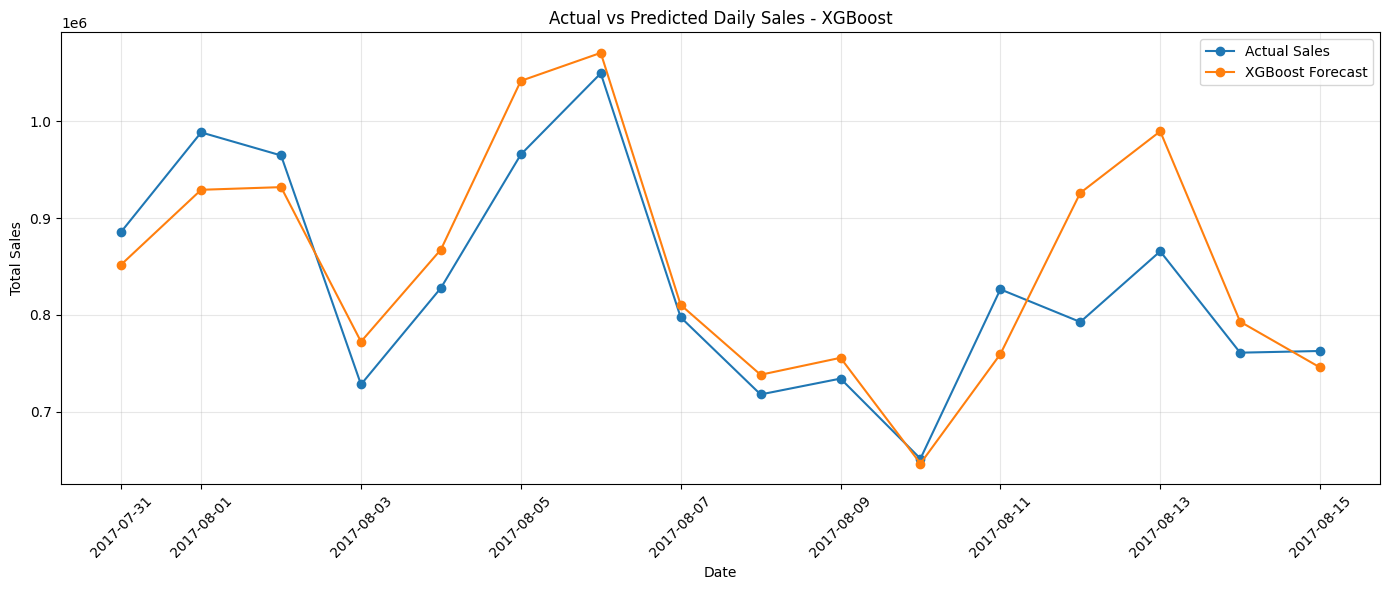

In [58]:

import matplotlib.pyplot as plt

# Aggregate actual and predicted sales by date
daily_forecast = (
    xgb_evaluation.groupby('date', as_index=False)
    .agg(
        actual_sales=('sales', 'sum'),
        predicted_sales=('y_pred', 'sum')
    )
)

# Plot actual vs predicted sales
plt.figure(figsize=(14, 6))

plt.plot(
    daily_forecast['date'],
    daily_forecast['actual_sales'],
    label='Actual Sales',
    marker='o'
)

plt.plot(
    daily_forecast['date'],
    daily_forecast['predicted_sales'],
    label='XGBoost Forecast',
    marker='o'
)

plt.title('Actual vs Predicted Daily Sales - XGBoost')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Forecast Visualization Insight

The Actual vs. Predicted Daily Sales visualization shows that the XGBoost model generally follows the overall movement of actual sales throughout the 16-day validation period. The predicted values capture several daily fluctuations, indicating that the model can represent changes in aggregated retail sales demand.

The forecast also shows some deviations from actual sales, particularly around periods of higher demand. In these instances, the model tends to slightly overestimate actual sales, suggesting that its predictions do not fully capture the magnitude of certain demand fluctuations.

From a business perspective, these forecasting deviations are important for inventory planning. Overestimation may lead to excess inventory and higher holding costs, while underestimation may increase the risk of stockouts. Therefore, both types of forecasting errors should be considered when translating predicted demand into inventory replenishment decisions.

Overall, the visualization provides an initial assessment of the XGBoost forecasting performance at the aggregated daily level. Further analysis at the store and product family levels can help identify demand patterns and prediction errors that may not be visible in the aggregated results.

#Inventory Planning Simulation

In [59]:

# Inventory planning assumptions
LEAD_TIME = 3
SAFETY_STOCK_PERCENTAGE = 0.20
REVIEW_PERIOD = 1

# 1. Sort forecast data
forecast_inventory = xgb_predictions.sort_values(
    ['store_nbr', 'family', 'date']
).copy()

# 2. Calculate average daily forecast demand
average_demand = (
    forecast_inventory
    .groupby(['store_nbr', 'family'], as_index=False)
    .agg(
        avg_daily_demand=('y_pred', 'mean'),
        total_forecast_demand=('y_pred', 'sum')
    )
)

# 3. Calculate lead-time demand from the first 3 forecast days
lead_time_demand = (
    forecast_inventory
    .groupby(['store_nbr', 'family'])
    .head(LEAD_TIME)
    .groupby(['store_nbr', 'family'], as_index=False)
    .agg(
        lead_time_demand=('y_pred', 'sum')
    )
)

# 4. Combine demand calculations
inventory_plan = average_demand.merge(
    lead_time_demand,
    on=['store_nbr', 'family'],
    how='left',
    validate='one_to_one'
)

# 5. Calculate safety stock
inventory_plan['safety_stock'] = (
    inventory_plan['lead_time_demand']
    * SAFETY_STOCK_PERCENTAGE
)

# 6. Calculate reorder point
inventory_plan['reorder_point'] = (
    inventory_plan['lead_time_demand']
    + inventory_plan['safety_stock']
)

# 7. Calculate target stock level
inventory_plan['target_stock_level'] = (
    inventory_plan['reorder_point']
    + inventory_plan['avg_daily_demand'] * REVIEW_PERIOD
)

# 8. Round inventory quantities upward
quantity_columns = [
    'avg_daily_demand',
    'lead_time_demand',
    'safety_stock',
    'reorder_point',
    'target_stock_level'
]

inventory_plan[quantity_columns] = (
    np.ceil(inventory_plan[quantity_columns])
)

# Display results
inventory_plan = inventory_plan.sort_values(
    'reorder_point',
    ascending=False
).reset_index(drop=True)

display(inventory_plan.head(10))

print("Number of store-family combinations:", len(inventory_plan))


,store_nbr,family,avg_daily_demand,total_forecast_demand,lead_time_demand,safety_stock,reorder_point,target_stock_level
0,45,GROCERY I,11072.00,177138.12,37150.00,7430.00,44580.00,55651.00
1,44,GROCERY I,10672.00,170751.00,34472.00,6895.00,41367.00,52039.00
2,47,GROCERY I,10421.00,166726.50,33887.00,6778.00,40665.00,51085.00
3,46,GROCERY I,10116.00,161844.70,30298.00,6060.00,36357.00,46473.00
4,44,PRODUCE,9670.00,154716.81,29895.00,5979.00,35874.00,45543.00
5,45,BEVERAGES,9487.00,151781.97,28938.00,5788.00,34725.00,44212.00
6,44,BEVERAGES,9771.00,156333.22,28297.00,5660.00,33956.00,43727.00
7,48,GROCERY I,8978.00,143639.94,27290.00,5458.00,32747.00,41725.00
8,47,BEVERAGES,8949.00,143173.05,26291.00,5259.00,31549.00,40497.00
9,3,GROCERY I,9150.00,146396.05,25870.00,5174.00,31044.00,40193.00


Number of store-family combinations: 1782


In [60]:

# Aggregate inventory requirements by product family
family_inventory = (
    inventory_plan
    .groupby('family', as_index=False)
    .agg(
        total_forecast_demand=('total_forecast_demand', 'sum'),
        avg_daily_demand=('avg_daily_demand', 'sum'),
        total_safety_stock=('safety_stock', 'sum'),
        total_reorder_point=('reorder_point', 'sum')
    )
    .sort_values(
        'total_forecast_demand',
        ascending=False
    )
)

display(family_inventory.head(10))


,family,total_forecast_demand,avg_daily_demand,total_safety_stock,total_reorder_point
12,GROCERY I,4069748.00,254385.00,163616.00,981596.00
3,BEVERAGES,3071575.00,191997.00,119279.00,715529.00
30,PRODUCE,1952230.88,122042.00,82590.00,495404.00
7,CLEANING,1221179.25,76352.00,50468.00,302658.00
8,DAIRY,756415.94,47301.00,29545.00,177135.00
5,BREAD/BAKERY,457911.53,28642.00,17471.00,104698.00
28,POULTRY,323161.44,20225.00,11677.00,69923.00
24,MEATS,312428.81,19555.00,11224.00,67221.00
18,HOME CARE,278140.66,17413.00,11034.00,66050.00
9,DELI,276178.41,17290.00,10464.00,62655.00


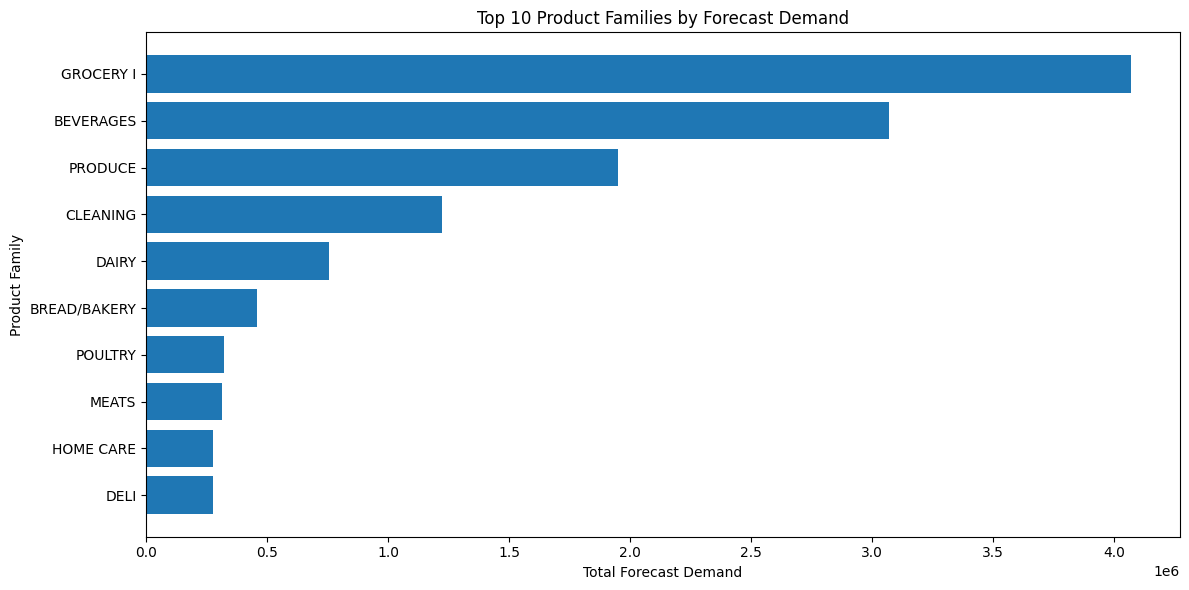

In [61]:

top_families = family_inventory.head(10).sort_values(
    'total_forecast_demand'
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_families['family'],
    top_families['total_forecast_demand']
)

plt.title('Top 10 Product Families by Forecast Demand')
plt.xlabel('Total Forecast Demand')
plt.ylabel('Product Family')
plt.tight_layout()
plt.show()


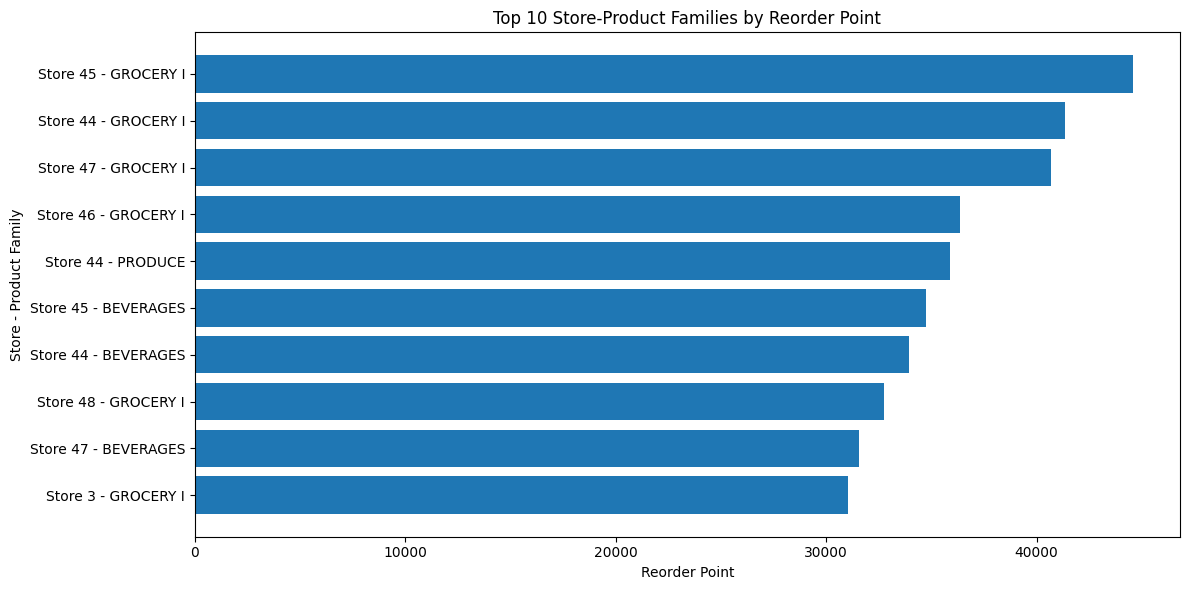

In [62]:

# Identify the top 10 store-family combinations by ROP
top_reorder = inventory_plan.nlargest(
    10, 'reorder_point'
).copy()

top_reorder['store_family'] = (
    'Store ' + top_reorder['store_nbr'].astype(str)
    + ' - ' + top_reorder['family']
)

top_reorder = top_reorder.sort_values('reorder_point')

plt.figure(figsize=(12, 6))

plt.barh(
    top_reorder['store_family'],
    top_reorder['reorder_point']
)

plt.title('Top 10 Store-Product Families by Reorder Point')
plt.xlabel('Reorder Point')
plt.ylabel('Store - Product Family')
plt.tight_layout()
plt.show()


## Inventory Planning Insight

The inventory planning simulation identifies GROCERY I as the product family with the highest forecast demand, reaching approximately 4.07 million units over the 16-day forecasting period. BEVERAGES and PRODUCE follow with approximately 3.07 million and 1.95 million units, respectively. These findings indicate that demand is concentrated in several major product families, which may require greater attention when planning inventory allocation.

At the store-product family level, the simulation covers 1,782 combinations across 54 stores and 33 product families. Store 45 – GROCERY I records the highest reorder point among the displayed results, at 44,580 units, consisting of 37,150 units of estimated lead-time demand and 7,430 units of safety stock. Its target stock level is estimated at 55,651 units.

These results demonstrate how sales forecasts can be translated into estimated inventory requirements through lead-time demand, safety stock, and reorder point calculations. The resulting estimates can support prioritization of inventory planning across stores and product families. However, since actual inventory levels and supplier lead times are unavailable, the results represent a scenario-based simulation rather than actual replenishment recommendations.

#Business Insights

### Business Insights

Based on the sales forecasting and inventory planning results, several business insights can be identified to support demand-driven inventory management.

**1. Demand Concentration Across Product Families**

GROCERY I recorded the highest forecast demand, reaching approximately 4.07 million units over the 16-day forecasting period. BEVERAGES and PRODUCE followed with approximately 3.07 million and 1.95 million units, respectively. This indicates that these product families represent major contributors to the projected sales volume. From a business perspective, inventory planning should give greater attention to these high-demand categories to support product availability and maintain operational continuity.

**2. Store-Level Inventory Prioritization**

The inventory planning simulation identified different reorder point requirements across 1,782 store-product family combinations. Among the displayed results, Store 45 – GROCERY I recorded the highest reorder point at 44,580 units, followed by Store 44 – GROCERY I at 41,367 units and Store 47 – GROCERY I at 40,665 units. These differences suggest that inventory requirements should be evaluated at the store and product family levels rather than applying a uniform inventory policy across all locations.

**3. Safety Stock as a Demand Buffer**

The simulation incorporates safety stock equal to 20% of estimated lead-time demand. This buffer provides additional inventory coverage against potential demand fluctuations under the selected assumptions. Product families and store combinations with higher forecast demand consequently require larger safety stock estimates. This approach illustrates how forecasting results can be translated into more structured inventory planning parameters.

**4. Forecast-Driven Replenishment Planning**

The XGBoost model achieved the lowest forecasting errors among the evaluated models, with a WAPE of 14.86%. Its predictions were subsequently used to estimate lead-time demand, safety stock, reorder points, and target stock levels. This demonstrates the potential of integrating machine learning-based demand forecasting with inventory planning to support data-driven replenishment decisions.

**5. Business Decision Support Implications**

The combined forecasting and inventory planning approach can help retail businesses identify high-demand product categories, prioritize inventory planning across store locations, and establish estimated replenishment thresholds. These insights can support more systematic inventory allocation and reduce reliance on decisions based solely on historical sales observations.

However, the inventory results are scenario-based estimates because actual inventory levels, supplier lead times, and replenishment costs are not available in the dataset. Therefore, the findings should be interpreted as decision-support estimates rather than actual operational replenishment recommendations.


#Conclusion & Limitations

## Conclusion

This project developed a retail sales forecasting and inventory planning framework using the Store Sales - Time Series Forecasting dataset from Corporación Favorita. The analysis covered 54 stores and 33 product families, with historical sales data from January 2013 to August 2017.

Three forecasting approaches were evaluated: Seasonal Naive, Random Forest Regressor, and XGBoost Regressor. Based on the 16-day validation period from July 31 to August 15, 2017, XGBoost achieved the best predictive performance, with an MAE of 69.4111, RMSE of 235.2038, and WAPE of 14.86%. These results indicate that XGBoost outperformed both the Seasonal Naive baseline and Random Forest in the evaluated forecasting period.

The selected XGBoost model was subsequently used to support an inventory planning simulation. Forecasted demand was translated into lead-time demand, safety stock, reorder points, and target stock levels across 1,782 store-product family combinations. The analysis identified GROCERY I, BEVERAGES, and PRODUCE as the product families with the highest forecast demand.

Overall, this project demonstrates how machine learning-based sales forecasting can be integrated with inventory planning calculations to provide demand-driven business insights. The resulting framework can support retail inventory prioritization and provide a foundation for more structured, data-driven replenishment planning.

## Limitations

Several limitations should be considered when interpreting the results of this project:

**1. Limited Validation Period**

The forecasting models were evaluated using a 16-day validation period from July 31 to August 15, 2017. Therefore, the reported performance may not fully represent forecasting accuracy across different seasons, longer periods, or changing retail conditions.

**2. Limited Training Data for Random Forest and XGBoost**

Due to computational constraints, Random Forest and XGBoost were trained using a sample of 300,000 observations rather than the entire available training dataset. Consequently, the models may not capture all patterns contained in the complete dataset.

**3. Absence of Actual Inventory Data**

The dataset does not provide actual stock levels, stockout records, inventory holding costs, or replenishment quantities. Therefore, the inventory planning component is implemented as a simulation rather than an evaluation of actual inventory management performance.

**4. Assumption-Based Inventory Parameters**

The inventory simulation uses an assumed supplier lead time of three days and safety stock equal to 20% of estimated lead-time demand. These parameters are not derived from actual supplier or operational records and may differ from real retail inventory requirements.

**5. Forecasting Granularity and Aggregation**

The forecasting process operates at the store, product family, and daily level. The aggregated daily sales visualization may conceal differences in demand patterns across individual stores and product families. More detailed analysis may be required for operational decisions at lower inventory levels.

**6. External Factors and Uncertainty**

Although the model incorporates available features such as promotions, holidays, store characteristics, and historical sales, other factors influencing retail demand may not be fully represented in the dataset. Changes in consumer preferences, local events, pricing strategies, and supply disruptions may affect actual demand beyond the model's predictions.